In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df  = pd.read_csv("Z_kc_house_data_NaN.csv")

print("Dataset loaded successfully")
print("Dataset shape:, df.shape")

df.head

Dataset loaded successfully
Dataset shape:, df.shape


<bound method NDFrame.head of        Unnamed: 0          id             date     price  bedrooms  bathrooms  \
0               0  7129300520  20141013T000000  221900.0       3.0       1.00   
1               1  6414100192  20141209T000000  538000.0       3.0       2.25   
2               2  5631500400  20150225T000000  180000.0       2.0       1.00   
3               3  2487200875  20141209T000000  604000.0       4.0       3.00   
4               4  1954400510  20150218T000000  510000.0       3.0       2.00   
...           ...         ...              ...       ...       ...        ...   
21608       21608   263000018  20140521T000000  360000.0       3.0       2.50   
21609       21609  6600060120  20150223T000000  400000.0       4.0       2.50   
21610       21610  1523300141  20140623T000000  402101.0       2.0       0.75   
21611       21611   291310100  20150116T000000  400000.0       3.0       2.50   
21612       21612  1523300157  20141015T000000  325000.0       2.0       0.75  

In [ ]:
pandas.core.generic.NDFrame.head
def head(n: int=5) -> Self
Return the first `n` rows.

This function returns the first `n` rows for the object based
on position. It is useful for quickly testing if your object
has the right type of data in it.

For negative values of `n`, this function returns all rows except
the last `|n|` rows, equivalent to ``df[:n]``.

If n is larger than the number of rows, this function returns all rows.

Parameters
----------
n : int, default 5
    Number of rows to select.

Returns
-------
same type as caller
    The first `n` rows of the caller object.

See Also
--------
DataFrame.tail: Returns the last `n` rows.

Examples
--------
>>> df = pd.DataFrame({'animal': ['alligator', 'bee', 'falcon', 'lion',
...                    'monkey', 'parrot', 'shark', 'whale', 'zebra']})
>>> df
      animal
0  alligator
1        bee
2     falcon
3       lion
4     monkey
5     parrot
6      shark
7      whale
8      zebra

Viewing the first 5 lines

>>> df.head()
      animal
0  alligator
1        bee
2     falcon
3       lion
4     monkey

Viewing the first `n` lines (three in this case)

>>> df.head(3)
      animal
0  alligator
1        bee
2     falcon

For negative values of `n`

>>> df.head(-3)
      animal
0  alligator
1        bee
2     falcon
3       lion
4     monkey
5     parrotpandas.core.generic.NDFrame.head
def head(n: int=5) -> Self
Return the first `n` rows.

This function returns the first `n` rows for the object based
on position. It is useful for quickly testing if your object
has the right type of data in it.

For negative values of `n`, this function returns all rows except
the last `|n|` rows, equivalent to ``df[:n]``.

If n is larger than the number of rows, this function returns all rows.

Parameters
----------
n : int, default 5
    Number of rows to select.

Returns
-------
same type as caller
    The first `n` rows of the caller object.

See Also
--------
DataFrame.tail: Returns the last `n` rows.

Examples
--------
>>> df = pd.DataFrame({'animal': ['alligator', 'bee', 'falcon', 'lion',
...                    'monkey', 'parrot', 'shark', 'whale', 'zebra']})
>>> df
      animal
0  alligator
1        bee
2     falcon
3       lion
4     monkey
5     parrot
6      shark
7      whale
8      zebra

Viewing the first 5 lines

>>> df.head()
      animal
0  alligator
1        bee
2     falcon
3       lion
4     monkey

Viewing the first `n` lines (three in this case)

>>> df.head(3)
      animal
0  alligator
1        bee
2     falcon

For negative values of `n`

>>> df.head(-3)
      animal
0  alligator
1        bee
2     falcon
3       lion
4     monkey
5     parrot

In [3]:

print("Column names:")
print(df.columns.tolist())

print("Dataset Information:")
df.info()

print("Missing values in each column:")
print(df.isnull().sum())

Column names:
['Unnamed: 0', 'id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     21613 non-null  int64  
 1   id             21613 non-null  int64  
 2   date           21613 non-null  str    
 3   price          21613 non-null  float64
 4   bedrooms       21600 non-null  float64
 5   bathrooms      21603 non-null  float64
 6   sqft_living    21613 non-null  int64  
 7   sqft_lot       21613 non-null  int64  
 8   floors         21613 non-null  float64
 9   waterfront     21613 non-null  int64  
 10  view           21613 non-null  int64  
 11  condition      21613 non-null 

In [ ]:

# Create a copy of the original dataset
df_clean = df.copy()

# 1. Remove the unnecessary index column
if 'Unnamed: 0' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Unnamed: 0'])

# 2. Convert date into datetime format
df_clean['date'] = pd.to_datetime(
    df_clean['date'],
    errors='coerce'
)

# 3. Check duplicate rows before removing them
print("Duplicate rows before cleaning:",
      df_clean.duplicated().sum())
# 4. Remove rows with missing important values
df_clean = df_clean.dropna(
    subset=['bedrooms', 'bathrooms', 'date']
)

# 5. Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# 6. Convert bedrooms into integer format
df_clean['bedrooms'] = df_clean['bedrooms'].astype(int)

# 7. Check the cleaned dataset
print("\nCleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nUpdated data types:")
print(df_clean.dtypes)

# Display first 5 cleaned records
df_clean.head()

In [13]:

# Basic Statistical Analysis

print("Total records:", len(df_clean))

print(f"Average house price: ${df_clean['price'].mean():,.2f}")

print(f"Median house price: ${df_clean['price'].median():,.2f}")

print(f"Minimum house price: ${df_clean['price'].min():,.2f}")

print(f"Maximum house price: ${df_clean['price'].max():,.2f}")

print("\nStatistical summary of house prices:")
print(df_clean['price'].describe())

Total records: 21597
Average house price: $540,202.92
Median house price: $450,000.00
Minimum house price: $78,000.00
Maximum house price: $7,700,000.00

Statistical summary of house prices:
count    2.159700e+04
mean     5.402029e+05
std      3.671337e+05
min      7.800000e+04
25%      3.220000e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64


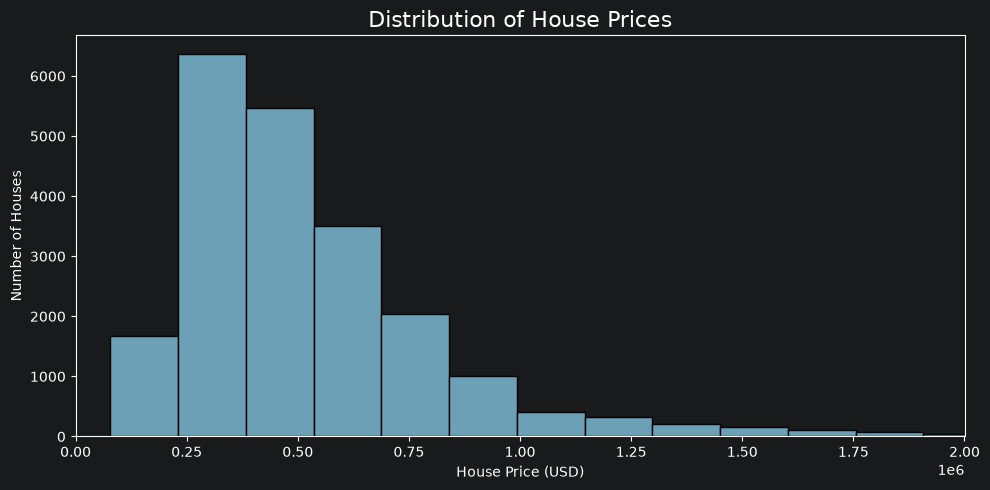

In [14]:

# House Price Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='price',
    bins=50,
    color='skyblue'
)

plt.title('Distribution of House Prices', fontsize=16)
plt.xlabel('House Price (USD)')
plt.ylabel('Number of Houses')
plt.xlim(0, 2_000_000)
plt.tight_layout()
plt.show()

Bedroom-wise analysis:
   bedrooms  average_price  house_count
0         1      318224.15          196
1         2      401372.68         2760
2         3      466232.08         9824
3         4      635419.50         6882
4         5      786599.83         1601
5         6      825520.64          272


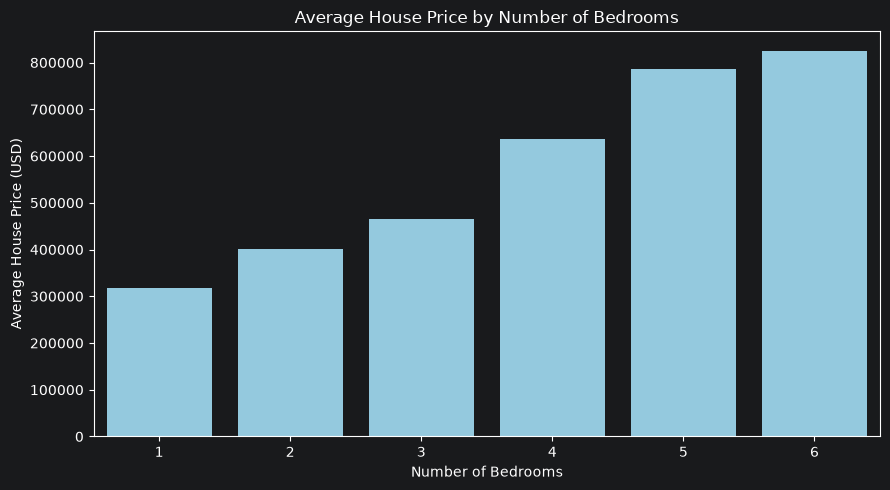

In [15]:

# Analyze houses with 1 to 6 bedrooms
bedroom_data = df_clean[
    df_clean['bedrooms'].between(1, 6)
]

# Calculate average price and number of houses
bedroom_analysis = (
    bedroom_data.groupby('bedrooms')
    .agg(
        average_price=('price', 'mean'),
        house_count=('price', 'count')
    )
    .reset_index()
)

print("Bedroom-wise analysis:")
print(bedroom_analysis.round(2))

# Create bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=bedroom_analysis,
    x='bedrooms',
    y='average_price',
    color='skyblue'
)

plt.title('Average House Price by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average House Price (USD)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

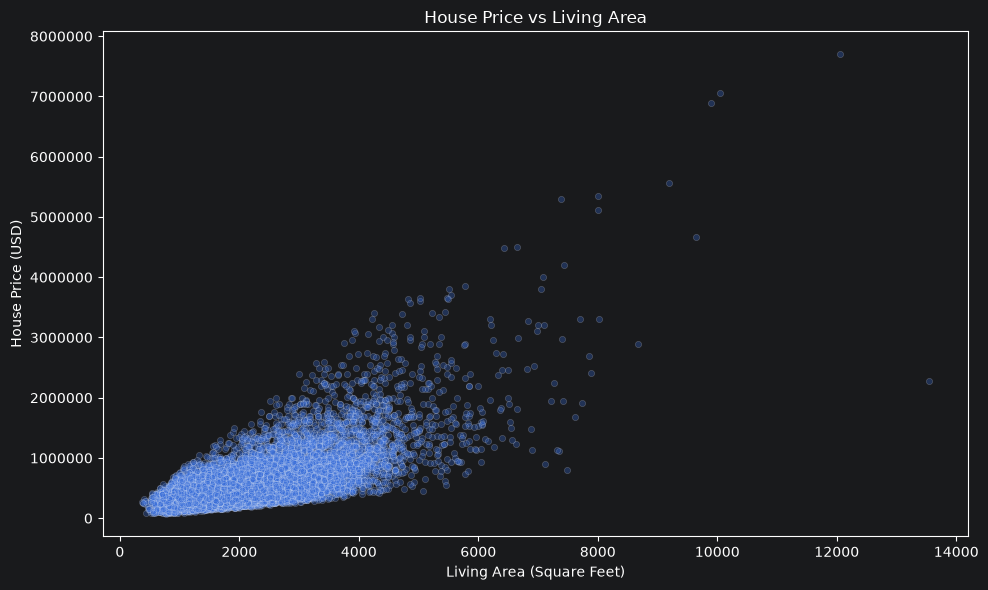

In [18]:

# Relationship between living area and house price

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='sqft_living',
    y='price',
    alpha=0.3,
    s=20
)

plt.title('House Price vs Living Area')
plt.xlabel('Living Area (Square Feet)')
plt.ylabel('House Price (USD)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()


Top 10 ZIP codes by average house price:
 zipcode  average_price  house_count
   98039     2160606.60           50
   98004     1355927.08          317
   98040     1194230.02          282
   98112     1095499.34          269
   98102      899395.37          104
   98109      879623.62          109
   98105      862825.23          229
   98006      859684.78          498
   98119      849448.02          184
   98005      810164.88          168


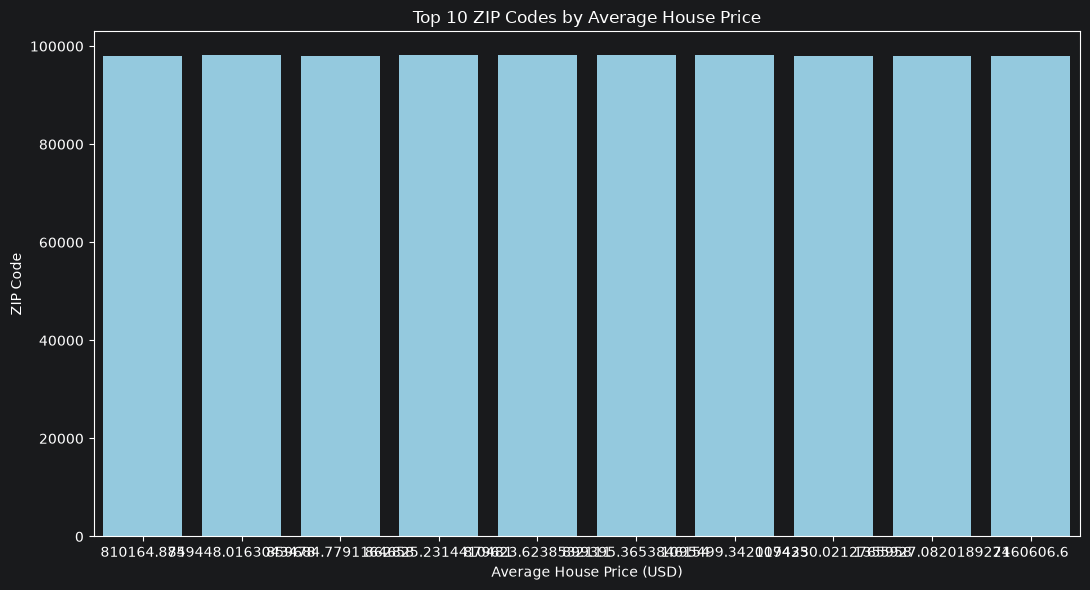

In [19]:


# Calculate average price and number of houses by ZIP code

location_analysis = (
    df_clean.groupby('zipcode')
    .agg(
        average_price=('price', 'mean'),
        house_count=('price', 'count')
    )
    .reset_index()
)

# Select top 10 ZIP codes by average house price
top_locations = (
    location_analysis
    .sort_values('average_price', ascending=False)
    .head(10)
    .sort_values('average_price', ascending=True)
)

print("Top 10 ZIP codes by average house price:")
print(
    top_locations.sort_values(
        'average_price', ascending=False
    ).round(2).to_string(index=False)
)

# Create horizontal bar chart
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_locations,
    x='average_price',
    y='zipcode',
    color='skyblue'
)

plt.title('Top 10 ZIP Codes by Average House Price')
plt.xlabel('Average House Price (USD)')
plt.ylabel('ZIP Code')

# Removed ticklabel_format to avoid the AttributeError
plt.tight_layout()
plt.show()


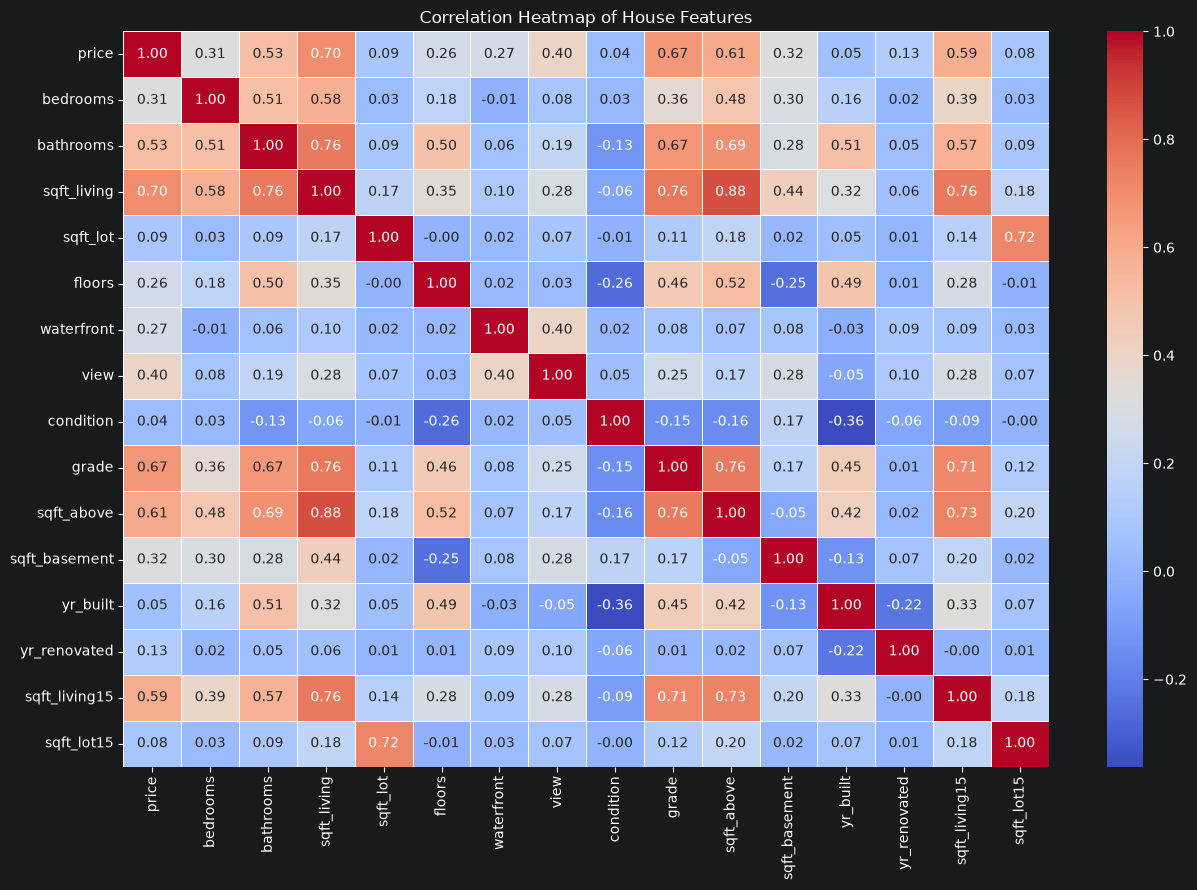

In [20]:
# Select important numerical columns
columns = [
    'price',
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'waterfront',
    'view',
    'condition',
    'grade',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated',
    'sqft_living15',
    'sqft_lot15'
]

# Calculate correlation
correlation = df_clean[columns].corr()

# Plot correlation heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of House Features')
plt.tight_layout()
plt.show()



In [21]:
# Find which features have the strongest correlation with price

price_correlation = (
    df_clean.corr(numeric_only=True)['price']
    .drop('price')
    .sort_values(ascending=False)
)

print("Correlation of features with house price:")
print(price_correlation.round(3))

Correlation of features with house price:
sqft_living      0.702
grade            0.668
sqft_above       0.605
sqft_living15    0.585
bathrooms        0.526
view             0.397
sqft_basement    0.324
bedrooms         0.309
lat              0.307
waterfront       0.266
floors           0.257
yr_renovated     0.126
sqft_lot         0.090
sqft_lot15       0.083
yr_built         0.054
condition        0.036
long             0.022
id              -0.017
zipcode         -0.053
Name: price, dtype: float64


Monthly House Price Analysis:
sale_month  average_price  houses_sold
   2014-05      548080.28         1768
   2014-06      557416.96         2178
   2014-07      544788.76         2211
   2014-08      536573.41         1939
   2014-09      529661.37         1771
   2014-10      539338.83         1876
   2014-11      522261.91         1409
   2014-12      524658.78         1470
   2015-01      525870.89          978
   2015-02      508451.66         1247
   2015-03      543977.19         1875
   2015-04      562119.84         2229
   2015-05      558126.81          646


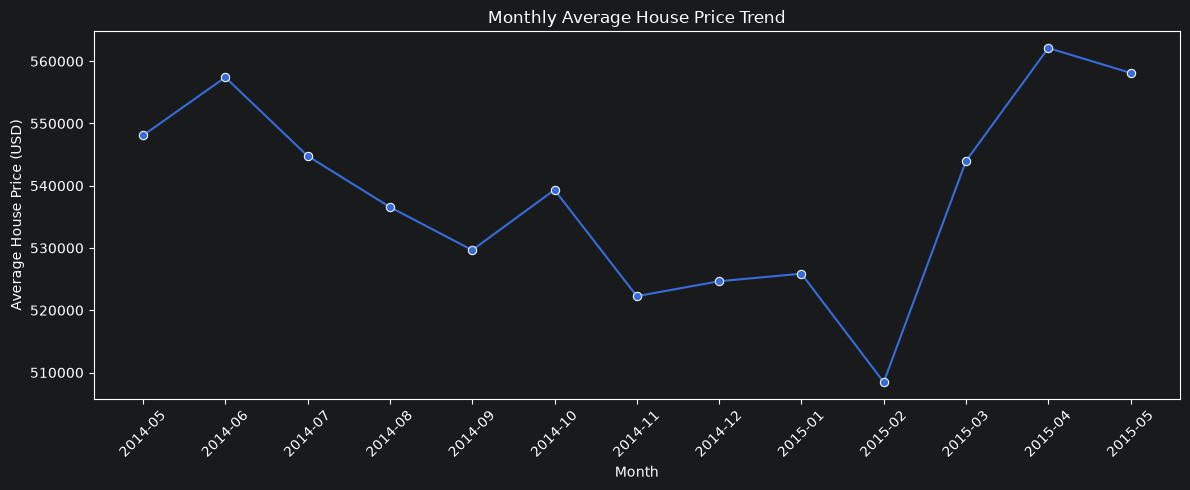

In [22]:


# Extract year and month from the date column
df_clean['sale_month'] = (
    df_clean['date'].dt.to_period('M').astype(str)
)

# Calculate monthly average price and number of sales
monthly_analysis = (
    df_clean.groupby('sale_month')
    .agg(
        average_price=('price', 'mean'),
        houses_sold=('id', 'count')
    )
    .reset_index()
)

print("Monthly House Price Analysis:")
print(monthly_analysis.round(2).to_string(index=False))

# Plot monthly average house prices
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_analysis,
    x='sale_month',
    y='average_price',
    marker='o'
)

plt.title('Monthly Average House Price Trend')
plt.xlabel('Month')
plt.ylabel('Average House Price (USD)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Real Estate Price Analysis — Conclusion

## Project Overview


This project analyzes house prices using Python, Pandas, NumPy, Matplotlib, and Seaborn. The dataset contains property prices, living area, bedrooms, bathrooms, location, condition, and other housing features.

## Data Cleaning


* Original dataset: 21,613 rows and 22 columns.
* Cleaned dataset: 21,597 rows and 21 columns.
* Removed the unnecessary Unnamed: 0 column.
* Handled missing values in bedrooms and bathrooms.
* Converted the date column to datetime format.
* Checked for duplicate records; none were found.


## Key Findings


1. The average house price was approximately
450,000.
2. House prices ranged from
7,700,000.
3. Three-bedroom properties were the most common among the analyzed bedroom groups.
4. The scatter plot showed a general positive relationship between living area and house price.
5. Average house prices differed across ZIP codes.
6. Monthly average prices fluctuated between May 2014 and May 2015.


## Conclusion


The analysis indicates that house prices vary with property size, bedroom count, location, and other housing characteristics. The visualizations help identify patterns and compare property groups. However, correlation does not prove causation,



## Tools Used


Python, Pandas, NumPy, Matplotlib, Seaborn, and Google Colab.